# QAOA and GIE Experiments

**Sources:**
1. Gravitationally Induced Entanglement (GIE) Experiments: 
    [Bose et al.](https://arxiv.org/abs/1707.06050),
    [Marletto \& Vedral](https://arxiv.org/abs/1707.06036)
2. Quantum Approximate Optimization Algorithm (QAOA): 
    [Alessandro Giovagnoli](https://arxiv.org/abs/2511.18377), 
    [Pennylane](https://pennylane.ai/codebook/variational-quantum-algorithms/quantum-approximate-optimization-algorithm),
    [IBM Quantum Platform](https://quantum.cloud.ibm.com/docs/en/tutorials/quantum-approximate-optimization-algorithm)
3. Circuit implementation: [Sabín (2023)](https://arxiv.org/abs/2302.04006)

## 0. Introduction

### 0.1 The quantum gravity debate

Quantum gravity — the unification of quantum mechanics and general relativity — has been an open problem for nearly a century. Two broad strategies are actively pursued. The first treats quantum theory as primary and seeks to **quantize gravity**, arriving at frameworks such as string theory and loop quantum gravity. The second reverses the priority and asks what changes would need to be made to quantum mechanics so that it becomes compatible with a classical spacetime — a **gravitization of quantum mechanics** in Penrose's phrase — leading to semiclassical gravity and related approaches.

The Bose et al. experiment belongs to a third, more modest programme: rather than proposing a full theory of quantum gravity, it asks a sharply focused empirical question. **Can the gravitational field act as a quantum mediator?** The experiment is designed so that a positive answer — detecting entanglement between two masses that interact exclusively through gravity — would provide direct evidence for the quantum nature of the gravitational field, without presupposing any specific model of quantum gravity.

### 0.2 What entanglement is — and why it matters here

Entanglement is a uniquely quantum phenomenon in which the state of a multi-particle system **cannot be written as a product of individual states**. If a two-spin state is entangled, measuring the spin of the first particle instantly constrains the possible outcomes for the second, even when they are spatially separated. This is not explainable by pre-existing correlations (hidden variables), as Bell's inequality shows: any local hidden-variable model predicts correlations bounded by 1, whereas entangled quantum states can violate this bound.

The operational signature of entanglement is that spin-correlation measurements in **complementary bases** yield results that are inconsistent with any separable (product) state. This is exactly what the Bose experiment measures.

### 0.3 The LOCC principle: the logical backbone

The experiment's argument rests on a fundamental theorem of quantum information theory:

> **Entanglement cannot be created by Local Operations and Classical Communication (LOCC).**

A local operation is any manipulation that acts only on one subsystem (one mass). Classical communication means the two subsystems exchange only classical information — no quantum channel, no shared quantum state. If two systems start in a separable (unentangled) state, no amount of local operations and classical back-and-forth can produce entanglement.

This is the key. In the Bose experiment:
- Each SG interferometer acts **locally** on its own mass.
- The only thing connecting the two masses is the **gravitational field**.
- If the experiment detects entanglement, the gravitational field must have acted as a **quantum channel** — not a classical one — because a classical channel is precisely LOCC, which cannot entangle.

Therefore: **entanglement ⟹ gravity is quantum**, without specifying which quantum theory of gravity is correct.

### 0.4 The circuit logic

The three-step SG interferometer maps onto a two-qubit circuit. Each qubit represents the spin of one test mass, with $|0\rangle = |\uparrow\rangle = L\text{-arm}$ and $|1\rangle = |\downarrow\rangle = R\text{-arm}$. The SG field gradient entangles spin with position ($H$ gate), gravity imprints position-dependent phases ($U_\text{grav}$), and the SG recombination transfers those phases back to spin. At the end, the spin state encodes the gravitational interaction history and can be measured to check whether the two masses became entangled.

A complementary circuit-based approach to gravitational entanglement is due to [Sabín (2023)](https://arxiv.org/abs/2302.04006), who digitally simulated the non-static harmonic-oscillator Hamiltonian $H_{AB} = -\hbar g(a^{\dagger 2}b^{\dagger 2} + a^2 b^2)$ — the double single-mode squeezing interaction that arises when gravity is treated as a quantum field — on IBM quantum hardware. That approach requires a 6-qubit Boson-qubit encoding (Somma mapping) and a Pauli decomposition into 8 commuting 4-qubit rotation blocks, whereas the Bose experiment reduces to a 2-qubit circuit with only 5 gates. The two circuits are complementary: the Bose circuit probes phase-encoded spin entanglement directly detectable via the witness $W$; the Sabín circuit simulates the underlying graviton-exchange mechanism that generates it.

### 0.5 Scope and limitations

This notebook implements the quantum-gravity side of the argument. The LOCC logic has a known gap: it assumes that the only alternative to a quantum gravitational field is a strictly classical channel in the Koopman sense. [Döner & Großardt (2022)](https://link.springer.com/article/10.1007/s10701-022-00619-0) construct an explicit counterexample — a hybrid model rooted in de Broglie–Bohm theory — in which a *classical* gravitational field sourced along Bohmian trajectories still generates entanglement, thereby predicting $W > 1$ without quantizing gravity. The distinction between this hybrid model and the quantum-gravity prediction becomes visible only through the parameter $R$ (the radius over which the wave function sources the gravitational potential): for finite $R$ the model predicts entanglement, while $R \to \infty$ recovers the non-entangling semiclassical (mean-field) limit. The circuit here corresponds to the $R \to 0$ limit, i.e. quantized gravity or the fully Bohmian hybrid. The next notebook in this series will implement the $R$-parametrised hybrid model and compare the two.

### 1. Environment

* `DiagonalGate` — to build the fixed-phase state from Eq. (6) directly from its amplitude vector, rather than hand-deriving single- and two-qubit rotation angles.

* `PauliEvolutionGate` / `LieTrotter` — to implement the QAOA cost unitary generated by the witness operator itself (a sum of two *commuting* two-qubit Paulis, so this evolution is implemented exactly, with no Trotter error).

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import DiagonalGate, PauliEvolutionGate
from qiskit.quantum_info import Statevector, SparsePauliOp, Operator
from qiskit.synthesis import LieTrotter
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

from qiskit_aer.primitives import Estimator as AerEstimator
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime.fake_provider import FakeBrisbane
from qiskit_ibm_runtime import EstimatorV2

print('Qiskit version:', __import__('qiskit').__version__)
print("Environment ready.")

Qiskit version: 2.4.0
Environment ready.


## 2. Connecting QAOA to GIE

### 2.1 Optimization of Entanglement Witness Operator: $W$

* **The physics problem:** [Bose et al. paper]((https://arxiv.org/abs/1707.06050)) ("Spin Entanglement Witness for Quantum Gravity") relies on witnessing entanglement between two spatial/spin qubits (micro-diamonds with NV centers) mediated by gravity. The proposed witness $\mathcal{W} = \vert{}\langle\sigma_x^{(1)}\otimes\sigma_z^{(2)}\rangle + \langle\sigma_y^{(1)}\otimes\sigma_y^{(2)}\rangle\vert{}$ relies on measuring spin correlations in complementary bases.

* **The QAOA Role:** In practice, experimental noise (Casimir-Polder background noise, thermal decoherence, spatial wavepacket overlap errors) alters the optimal measurement basis. One can formulate finding the optimal measurement witness operator or state preparation pulses under noise constraints as a variational parameter optimization problem. QAOA can be used to optimize state preparation unitaries or parameter sweeps to maximize witness sensitivity ([Alessandro Giovagnoli](https://arxiv.org/abs/2511.18377)).

### 2.2 Mapping Discrete Quantum Gravity / Spin Systems to QUBO

* **The Physics Problem:** The Bose et al. protocol dually maps spatial paths to effective "orbital qubits". The interaction Hamiltonian between two spatial paths can be reduced to a discretized spin-spin interaction Hamiltonian of the form $H_f = \sum_{ij} J_{ij}\sigma_z^i \sigma_z^j + \sum_i h_i \sigma_z^i$.

* **The QAOA Role:** As detailed in the QAOA guide, any binary quadratic interaction cost function (QUBO) can be mapped directly to an Ising spin Hamiltonian $\mathcal{H}_f = \sum a^{ij}\sigma_z^i\sigma_z^j + \sum b^i\sigma_z^i$. Using QAOA to simulate or optimize discrete multi-qubit spatial path states under weak gravitational coupling is a valid application of Variational Quantum Algorithms (VQAs) ([Alessandro Giovagnoli](https://arxiv.org/abs/2511.18377), ). 

### 2.3 Potential Misconceptions to Avoid

1. Continuous vs. Discrete Dynamics: The gravitational entanglement phase $\Delta\phi \sim \frac{G m_1 m_2 \tau}{\hbar d}$ is continuous phase accumulation. QAOA is designed for discrete combinatorial optimization problems (Max-Cut, Knapsack, PUBO). To use QAOA, we must discretize the spatial/spin configuration space into qubits. 

2. Quantum Simulation vs. Optimization: Evolving a state under a physical gravitational Hamiltonian is Analog Quantum Simulation or standard Trotterized time evolution. QAOA explicitly alternates between a cost Hamiltonian $\mathcal{H}_C$ and a mixer Hamiltonian $\mathcal{H}_M$ to find a ground state using classical parameter optimization $(\vec{\beta}, \vec{\gamma})$.

## 3. Physics Recap: From S-G Interferometry to a Two-Qubit State

Two neutral test masses $m_1, m_2$ fall through adjacent Stern-Gerlach interferometers. Each mass' internal spin is used to spatially split its wavepacket (Eq. 4 of the paper):
$$
|C\rangle_j\,\frac{1}{\sqrt2}\big(|\!\uparrow\rangle_j+|\!\downarrow\rangle_j\big)
\;\longrightarrow\;
\frac{1}{\sqrt2}\big(|L,\uparrow\rangle_j+|R,\downarrow\rangle_j\big), \qquad j=1,2.
$$
The two branches are held apart for a hold time $\tau$ (step 2), during which the *purely gravitational* interaction between the masses imprints relative phases on the four joint branches ($LL, LR, RL, RR$) because each branch pair sits at a different mutual separation. Step 3 recombines the wavepackets, mapping the accumulated orbital phase onto the *spin* degree of freedom (Eq. 5), giving the final state (Eq. 6 of the paper):
$$
|\Psi(t_{\rm end})\rangle_{12} = \frac{1}{\sqrt2}\Big[
|\!\uparrow\rangle_1\tfrac{1}{\sqrt2}\big(|\!\uparrow\rangle_2+e^{i\Delta\phi_{LR}}|\!\downarrow\rangle_2\big)
+|\!\downarrow\rangle_1\tfrac{1}{\sqrt2}\big(e^{i\Delta\phi_{RL}}|\!\uparrow\rangle_2+|\!\downarrow\rangle_2\big)
\Big]\otimes|C\rangle_1|C\rangle_2.
$$
Because the orbital factor $|C\rangle_1|C\rangle_2$ is a simple product state that is completely disentangled from the spins, it can be dropped and we are left with a **normalized two-qubit spin state**
$$
|\Psi_{\rm spin}\rangle = \frac{1}{2}\Big[
|\!\uparrow\uparrow\rangle + e^{i\Delta\phi_{LR}}|\!\uparrow\downarrow\rangle
+ e^{i\Delta\phi_{RL}}|\!\downarrow\uparrow\rangle + |\!\downarrow\downarrow\rangle\Big],
$$
which we will identify with the qubit basis $|\!\uparrow\rangle\to|0\rangle$, $|\!\downarrow\rangle\to|1\rangle$, qubit 0 = mass 1, qubit 1 = mass 2.

**Entanglement witness.** The paper certifies entanglement — and thereby the quantum coherent nature of the gravitational mediator — via
$$
W = \big|\,\langle\sigma_x^{(1)}\otimes\sigma_z^{(2)}\rangle + \langle\sigma_y^{(1)}\otimes\sigma_y^{(2)}\rangle\,\big|,
$$
with $W>1$ certifying entanglement (a bound derived by Cauchy–Schwarz for LOCC/separable states; here we take the bound as given and focus on how large a $W$ different circuits can produce).

**Physical operating point.** For $m_1\sim m_2\sim 10^{-14}\,$ kg, $d\sim450\,\mu$ m, $\Delta x \sim 250 \mu$, and a hold time $\tau\sim 2.5\,$ s, the paper quotes
$$
\Delta\phi_{LR}\sim -0.2, \qquad \Delta\phi_{RL}\sim 0.7,
$$
and states that "*this phase accumulation alone gives $W\sim1.16$*."

In [ ]:
# Physical parameters:
#  m  = 1e-14 kg   (microdiamond, ~10 μm radius)
#  d  = 450 μm  (trap separation)
#  Δx = 250 μm  (arm splitting)
#  τ  = 2.5 s    (step 2 holding time)

# Physical phase values quoted in the paper for tau ~ 2.5 s, d ~ 450 micron
dphi_LR_paper = -0.2
dphi_RL_paper = 0.7

# The two-qubit spin-state amplitude vector, following Eq. (6) with |C>_1|C>_2 dropped.
#   dphi_LR = phase for |L>_1 |R>_2
#   dphi_RL = phase for |R>_1 |L>_2

# We identify:
#   |L> = |up> = |0>
#   |R> = |down> = |0>
# and:
#   q0 = mass 1
#   q1 = mass 2
# States:
#   [|q0 q1>] = [|00>, |01>, |10>, |11>] 
#             = [|up,up>, |up,down>, |down,up>, |down,down>]
#             = [|L,L>, |L,R>, |R,L>, |R,R>]

def bose_amplitudes(dphi_LR, dphi_RL):
    return 0.5 * np.array([
        1,                      # |00> = |LL>    
        np.exp(1j * dphi_RL),   # |01> = |RL>
        np.exp(1j * dphi_LR),   # |01> = |LR>
        1,                      # |11> = |RR>
    ])

expected_amplitudes = bose_amplitudes(dphi_LR_paper, dphi_RL_paper)
states = ["|00> (|L,L>)", "|01> (|R,L>)", "|10> (|L,R>)", "|11> (|R,R>)"]

print("Target Amplitude Vector:")
print("-" * 45)
for state, amp in zip(states, expected_amplitudes):
    print(f"{state:<15} : {amp:+.6f}")

print("-" * 45)
print(f"Normalization check sum(|amp|^2) = {np.sum(np.abs(expected_amplitudes)**2):.6f}")

Target Amplitude Vector:
---------------------------------------------
|00> (|L,L>)    : +0.500000+0.000000j
|01> (|R,L>)    : +0.382421+0.322109j
|10> (|L,R>)    : +0.490033-0.099335j
|11> (|R,R>)    : +0.500000+0.000000j
---------------------------------------------
Normalization check sum(|amp|^2) = 1.000000


**Reading the output:** the norm should be exactly 1 (up to floating point), confirming this is a valid quantum state on its own once the orbital factor is dropped. Note that $\Delta\phi_{LR}$ multiplies the $|01\rangle = |\!\uparrow\downarrow\rangle$ amplitude and $\Delta\phi_{RL}$ multiplies the $|10\rangle=|\!\downarrow\uparrow\rangle$ amplitude — the $|00\rangle$ and $|11\rangle$ amplitudes are always exactly $1/2$ (real, unphased).

## 4. Cost and Mixer Hamiltonians ($H_C, H_M$)

### 4.1 Bose Experiment Hamilationian

For the Bose experiment the physical Hamiltonian is defined as:
$$
    \hat{H} = -\frac{\hbar^2}{2m_1} \nabla_1^2 - \frac{\hbar^2}{2m_2} \nabla_2^2 - \frac{G m_1 m_2}{|\hat{x}_1 - \hat{x}_2|}
$$
Considering the setup of the experiment and using work of [Sabín (2023)](https://arxiv.org/abs/2302.04006), we can build up the circuit of it as:

U_grav matrix match: True
Diagonal phases (rad):
  |LL⟩=|00⟩: phase = +0.0000 rad
  |RL⟩=|01⟩: phase = +0.7000 rad
  |LR⟩=|10⟩: phase = -0.2000 rad
  |RR⟩=|11⟩: phase = +0.0000 rad


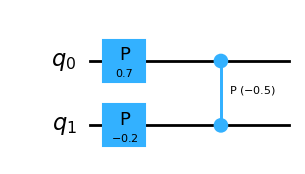

In [11]:
# ==========================================================
# Quantum Circuit Implementation (Qiskit)
# ==========================================================
def build_U_grav(dphi_RL, dphi_LR):
    """
    Gravitational phase gate U_grav = diag(1, e^{iΔφ_RL}, e^{iΔφ_LR}, 1).
    
    Qubit mapping:
        q0 = mass 1 |0⟩=|L⟩, |1⟩=|R⟩
        q1 = mass 2 |0⟩=|L⟩, |1⟩=|R⟩
    """
    qc = QuantumCircuit(2, name='U_grav')
    
    # Target: Phase e^{iΔφ_RL} on state |01> (q1=0, q0=1) -> mass 1=R, mass 2=L
    qc.p(dphi_RL, 0)
    
    # Target: Phase e^{iΔφ_LR} on state |10> (q1=1, q0=0) -> mass 1=L, mass 2=R
    qc.p(dphi_LR, 1)
    
    # Target: Phase 1 (0 rad) on state |11> -> cancel double counting from p gates
    qc.cp(-(dphi_RL + dphi_LR), 0, 1)
    
    return qc

# Verify U_grav matrix against theoretical target
U_gate = Operator(build_U_grav(dphi_RL_paper, dphi_LR_paper)).data
U_target = np.diag([1, np.exp(1j * dphi_RL_paper), np.exp(1j * dphi_LR_paper), 1])

print(f"U_grav matrix match: {np.allclose(U_gate, U_target)}")
print("Diagonal phases (rad):")
for label, v in zip(['|LL⟩=|00⟩', '|RL⟩=|01⟩', '|LR⟩=|10⟩', '|RR⟩=|11⟩'], np.diag(U_gate)):
    print(f"  {label}: phase = {np.angle(v):+.4f} rad")

display(build_U_grav(dphi_RL_paper, dphi_LR_paper).draw('mpl', style='iqp', fold=False))

Bose et al. SG interferometer circuit:


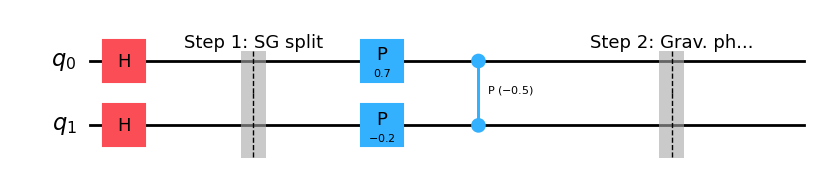

Gate count: {'h': 2, 'barrier': 2, 'p': 2, 'cp': 1}


In [13]:
def build_bose_circuit(dphi_RL, dphi_LR, measure_basis=None, add_measure=False):
    """
    Full Bose et al. SG interferometer circuit.
    """
    nclbits = 2 if add_measure else 0
    qc = QuantumCircuit(2, nclbits)

    # Step 1: SG splitting (Hadamard layer)
    qc.h(0)
    qc.h(1)
    qc.barrier(label='Step 1: SG split')

    # Step 2: Gravitational phase accumulation
    qc.p(dphi_RL, 0)
    qc.p(dphi_LR, 1)
    qc.cp(-(dphi_RL + dphi_LR), 0, 1)
    qc.barrier(label='Step 2: Grav. phase')

    # Measurement basis transformations
    if measure_basis == 'ZX':
        qc.h(0)
    elif measure_basis == 'YY':
        qc.rx(-np.pi / 2, 0)
        qc.rx(-np.pi / 2, 1)

    if add_measure:
        qc.measure(0, 0)
        qc.measure(1, 1)

    return qc

qc_main = build_bose_circuit(dphi_RL_paper, dphi_LR_paper)
print("Bose et al. SG interferometer circuit:")
display(qc_main.draw('mpl', style='iqp', fold=False))
print(f"Gate count: {dict(qc_main.count_ops())}")

### 4.2 Simplest Bose cost Hamiltonian ($H_C$)

By defining:
$$
    \alpha = \Delta \phi_{LR}, \quad \beta = \Delta \phi_{RL}
$$
We want to gather operator of the $H_C$:
$$
    U_C = e^{-i\gamma H_C}
$$
to generate,
$$
    \text{diag} (1, e^{i\beta}, e^{i\alpha}, 1), \quad \text{when} \, \gamma = 1
$$
One convenient choice is:
$$
    H_C = \begin{pmatrix}
    0 & 0 & 0 & 0\\
    0 & -\beta & 0 & 0\\
    0 & 0 & -\alpha & 0\\
    0 & 0 & 0 & 0
    \end{pmatrix}
$$
Then,
$$
    e^{-iH_C} = \begin{pmatrix}
    1 & 0 & 0 & 0\\
    0 & e^{i\beta} & 0 & 0\\
    0 & 0 & e^{i\alpha} & 0\\
    0 & 0 & 0 & 1
    \end{pmatrix}
$$
Which is exactly what we need. For QAOA we want a Pauli decomposition, and $Z_0$ for mass $1$ and $Z_1$ for mass $2$,
$$
    H_C = -\frac{\alpha + \beta}{4} I + -\frac{\beta - \alpha}{4} Z_0 + -\frac{\alpha - \beta}{4} Z_1 + -\frac{\alpha + \beta}{4} Z_0 Z_1
$$
The identity term only produces a *global phase*, so for the quantum dynamics we can drop it:
$$
    H'_C = -\frac{\beta - \alpha}{4} Z_0 + -\frac{\alpha - \beta}{4} Z_1 + -\frac{\alpha + \beta}{4} Z_0 Z_1
$$
or more compactly,
$$
    H'_C = -\frac{\Delta \phi_{RL} - \Delta \phi_{LR}}{4} (Z_0 - Z_1) + -\frac{\Delta \phi_{RL} + \Delta \phi_{LR}}{4} Z_0 Z_1
$$
This is the Bose gravitational phase cost Hamiltonian that we will use for the QAOA implementation. Checking it explicitly with the values shared by Bose et al., $\Delta \phi_{LR} = -0.2, \, \Delta \phi_{RL} = 0.7$:
$$
    \frac{\beta - \alpha}{4} = \frac{0.7 - (-0.2)}{4} = 0.225, \, \text{and}\, \frac{\alpha + \beta}{4} = \frac{-0.2 + 0.7}{4} = 0.125
$$
Therefore
$$
    H'_C = 0.225 Z_0 - 0.225 Z_1 + 0.125 Z_0Z_1
$$
The eigenvalues (energies) after putting back identity term:
$$
    \begin{align}
        E_{00} &= 0.125,\\
        E_{01} &= -0.575,\\
        E_{10} &= 0.325,\\
        E_{11} &= 0.125
    \end{align}
$$
Subtracting the common 0.125 gives $[0, -0.7, 0.2, 0]$, but more clearly using *full Hamiltonian* in the implementation for our goal of reproducing the phase state exactly:
$$
    H_C = -\frac{\alpha + \beta}{4} I + -\frac{\beta - \alpha}{4} Z_0 + -\frac{\alpha - \beta}{4} Z_1 + -\frac{\alpha + \beta}{4} Z_0 Z_1
$$
For $\alpha = -0.2$, $\beta = 0.7$,
$$
    H_C = -0.125 I + 0.225 Z_0 + 0.225 Z_1 + 0.125 Z_0 Z_1
$$
its four eigenvalues are exactly
$$
    [0, -0.7, 0.2, 0]
$$
Hence,
$$
    e^{-iH_C} = \text{diag}(1, e^{i0.7}, e^{-i0.2}, 1),
$$
which is precisely,
$$
    [1, e^{i\Delta \phi_{RL}}, e^{i\Delta \phi_{LR}}, 1].
$$

### 4.3 Mixer Hamiltonian ($H_M$)
For ordinary QAOA, we need
$$
    H_M = \sum_i X_i
$$
For Bose experiment, which has two spins values ;
$$
    U_M (\eta) = e^{-i\eta H_M} = e^{-\eta X_0} + e^{-\eta X_1}
$$
because; $[X_0, X_1] = 0$
```
    qc.rx(2 * eta, 0)
    qc.rx(2 * eta, 1)
```
and because; $R_X(\theta) = e^{-i\theta X/2}$
We get,
$$
    R_X (2\eta) = e^{-i\eta X}
$$
And with this can move on to gathering circuit for the Bose experiment but this time implementing QAOA, hence using $H_C$ and $H_M$ in the process.

In [ ]:
# ============================================================
# 2. HAMILTONIAN BUILDERS
# ============================================================

def build_bose_cost_hamiltonian(dphi_LR: float, dphi_RL: float) -> SparsePauliOp:
    """
    Builds full Bose Cost Hamiltonian H_C such that:
    <00|H_C|00> = 0
    <01|H_C|01> = -dphi_RL
    <10|H_C|10> = -dphi_LR
    <11|H_C|11> = 0
    """
    c0  = -(dphi_RL + dphi_LR) / 4.0
    c1  =  (dphi_RL - dphi_LR) / 4.0  # IZ (Z on q0)
    c2  =  (dphi_LR - dphi_RL) / 4.0  # ZI (Z on q1)
    c12 =  (dphi_RL + dphi_LR) / 4.0  # ZZ

    return SparsePauliOp.from_list([
        ("II", c0),
        ("IZ", c1),
        ("ZI", c2),
        ("ZZ", c12)
    ])

In [41]:
# ============================================================
# 3. QAOA CIRCUIT GENERATOR
# ============================================================

def build_qaoa_circuit(gamma: float, beta: float, cost_h: SparsePauliOp) -> QuantumCircuit:
    """Builds 1-layer QAOA circuit: U_M(beta) * U_C(gamma) * |++>."""
    qc = QuantumCircuit(2, name="Bose_QAOA")

    # Initial state |++>
    qc.h(0)
    qc.h(1)
    qc.barrier()

    # Cost Unitary: U_C(gamma) = exp(-i * gamma * H_C)
    for pauli_str, coeff in cost_h.to_list():
        weight = float(np.real(coeff))
        if pauli_str == "II":
            qc.global_phase -= gamma * weight
        elif pauli_str == "IZ":
            qc.rz(2 * gamma * weight, 0)
        elif pauli_str == "ZI":
            qc.rz(2 * gamma * weight, 1)
        elif pauli_str == "ZZ":
            qc.rzz(2 * gamma * weight, 0, 1)

    qc.barrier()

    # Mixer Unitary: U_M(beta) = exp(-i * beta * H_M)
    qc.rx(2 * beta, 0)
    qc.rx(2 * beta, 1)

    return qc

In [42]:
def calculate_entanglement_witness(state: Statevector) -> float:
    """
    Bose et al. entanglement witness: W = |<X_1 Z_2> + <Y_1 Y_2>|
    With q0 = particle 1 and q1 = particle 2, Qiskit's Pauli-string representation is:
        X_1 Z_2  -> "ZX"
        Y_1 Y_2  -> "YY"
    Entanglement is witnessed when W > 1.
    """

    op_xz = SparsePauliOp.from_list([("ZX", 1.0)])
    op_yy = SparsePauliOp.from_list([("YY", 1.0)])

    exp_xz = state.expectation_value(op_xz).real
    exp_yy = state.expectation_value(op_yy).real

    W = abs(exp_xz + exp_yy)

    return W

1. HAMILTONIAN EIGENVALUE VERIFICATION
Calculated Spectrum:  [-0.7 -0.   0.   0.2]
Expected Spectrum:    [-0.7  0.   0.   0.2]
Spectrum Match:       True

2. EXACT STATE PREPARATION (gamma = 1.0, beta = 0.0)
State Preparation Fidelity: 1.000000
Entanglement Witness (W):   0.2968  (Entangled if W > 1.0)

3. VARIATIONAL QAOA LAYER (gamma = 1.0, beta = 0.5)


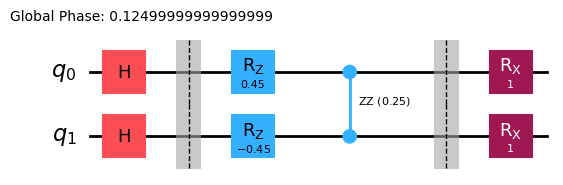

In [ ]:
def main():
    print("=" * 65)
    print("1. HAMILTONIAN EIGENVALUE VERIFICATION")
    print("=" * 65)

    cost_h = build_bose_cost_hamiltonian(dphi_LR_paper, dphi_RL_paper)
    h_c_matrix = cost_h.to_matrix()
    
    # Sort eigenvalues to match sorted output of eigvalsh
    eigenvalues = np.linalg.eigvalsh(h_c_matrix)
    expected_energies = np.sort([0.0, -dphi_RL_paper, -dphi_LR_paper, 0.0])

    print("Calculated Spectrum: ", np.round(eigenvalues, 4))
    print("Expected Spectrum:   ", np.round(expected_energies, 4))
    print("Spectrum Match:      ", np.allclose(eigenvalues, expected_energies))

    print("\n" + "=" * 65)
    print("2. EXACT STATE PREPARATION (gamma = 1.0, beta = 0.0)")
    print("=" * 65)

    target_sv = Statevector(bose_amplitudes(dphi_LR_paper, dphi_RL_paper))
    exact_qaoa_qc = build_qaoa_circuit(gamma=1.0, beta=0.0, cost_h=cost_h)
    exact_sv = Statevector(exact_qaoa_qc)

    w_value = calculate_entanglement_witness(exact_sv)
    fidelity = np.abs(target_sv.inner(exact_sv)) ** 2

    print(f"State Preparation Fidelity: {fidelity:.6f}")
    print(f"Entanglement Witness (W):   {w_value:.4f}  (Entangled if W > 1.0)")

    print("\n" + "=" * 65)
    print("3. VARIATIONAL QAOA LAYER (gamma = 1.0, beta = 0.5)")
    print("=" * 65)

    qaoa_qc = build_qaoa_circuit(gamma=1.0, beta=0.5, cost_h=cost_h)
    display(qaoa_qc.draw('mpl', style='iqp', fold=False))

if __name__ == "__main__":
    main()

Target system: fake_brisbane (127 qubits)


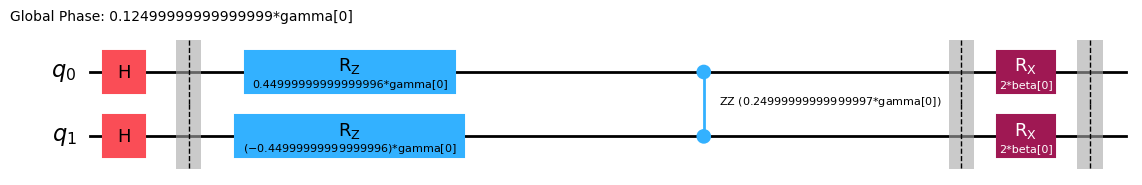

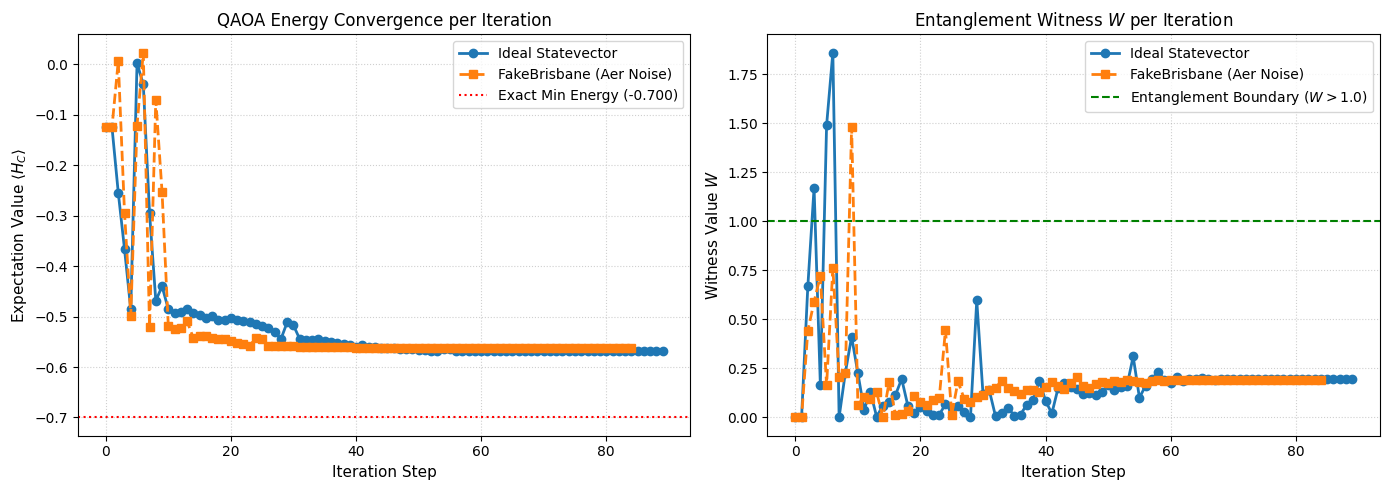

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp, Statevector

# Primitives & Simulator Engines
from qiskit.primitives import StatevectorEstimator
from qiskit_aer.primitives import EstimatorV2 as AerEstimatorV2
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel

# Fake Backend & Transpiler
from qiskit_ibm_runtime.fake_provider import FakeBrisbane
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager


# --- 1. Bose et al. Physical Parameters & Operators ---
dphi_LR_paper = -0.2
dphi_RL_paper = 0.7

def build_bose_cost_hamiltonian(dphi_LR: float, dphi_RL: float) -> SparsePauliOp:
    """
    Builds full Bose Cost Hamiltonian H_C such that:
    <00|H_C|00> = 0,  <01|H_C|01> = -dphi_RL
    <10|H_C|10> = -dphi_LR, <11|H_C|11> = 0
    """
    c0  = -(dphi_RL + dphi_LR) / 4.0
    c1  =  (dphi_RL - dphi_LR) / 4.0  # IZ (Z on q0)
    c2  =  (dphi_LR - dphi_RL) / 4.0  # ZI (Z on q1)
    c12 =  (dphi_RL + dphi_LR) / 4.0  # ZZ

    return SparsePauliOp.from_list([
        ("II", c0),
        ("IZ", c1),
        ("ZI", c2),
        ("ZZ", c12)
    ])

def build_witness_operators() -> tuple[SparsePauliOp, SparsePauliOp]:
    """Returns SparsePauliOps for calculating W = |<ZX> - <YY>|."""
    op_xz = SparsePauliOp.from_list([("ZX", 1.0)])  # Z on q1, X on q0
    op_yy = SparsePauliOp.from_list([("YY", 1.0)])  # Y on q1, Y on q0
    return op_xz, op_yy


# --- 2. Build QAOA Parameterized Circuit Template ---
def qaoa_bose_circuit_template(p: int, cost_h: SparsePauliOp) -> QuantumCircuit:
    """
    Creates a symbolic QAOA ansatz for the 2-qubit Bose gravity setup.
    """
    gammas = ParameterVector('gamma', p)
    betas = ParameterVector('beta', p)

    qc = QuantumCircuit(2, name="Bose_QAOA")
    qc.h([0, 1])  # Initial state |++>
    qc.barrier()

    for layer in range(p):
        gamma = gammas[layer]
        beta = betas[layer]

        # Cost Layer Evolution: exp(-i * gamma * H_C)
        for pauli_str, coeff in cost_h.to_list():
            weight = float(np.real(coeff))
            if pauli_str == "II":
                qc.global_phase -= gamma * weight
            elif pauli_str == "IZ":
                qc.rz(2 * gamma * weight, 0)
            elif pauli_str == "ZI":
                qc.rz(2 * gamma * weight, 1)
            elif pauli_str == "ZZ":
                qc.rzz(2 * gamma * weight, 0, 1)

        qc.barrier()

        # Mixer Layer Evolution: exp(-i * beta * H_M)
        qc.rx(2 * beta, 0)
        qc.rx(2 * beta, 1)
        qc.barrier()

    return qc


# --- 3. Objective Function Factory ---
def make_cost_function(circuit_template, cost_op, estimator, pass_manager, history_energy, history_witness):
    """
    Transpiles ansatz to backend layout once, then evaluates <H_C> 
    and witness W at each iteration step.
    """
    op_xz, op_yy = build_witness_operators()

    if pass_manager is not None:
        transpiled_circuit = pass_manager.run(circuit_template)
        mapped_cost_op = cost_op.apply_layout(transpiled_circuit.layout)
        mapped_xz = op_xz.apply_layout(transpiled_circuit.layout)
        mapped_yy = op_yy.apply_layout(transpiled_circuit.layout)
    else:
        transpiled_circuit = circuit_template
        mapped_cost_op = cost_op
        mapped_xz = op_xz
        mapped_yy = op_yy

    def cost_func(params):
        bound_circuit = transpiled_circuit.assign_parameters(params)
        
        # Evaluate energy <H_C> and witness terms <ZX>, <YY> in a single batch call
        job = estimator.run([(bound_circuit, [mapped_cost_op, mapped_xz, mapped_yy])])
        results = job.result()[0].data.evs

        energy = float(results[0])
        exp_xz = float(results[1])
        exp_yy = float(results[2])
        witness_val = abs(exp_xz - exp_yy)

        history_energy.append(energy)
        history_witness.append(witness_val)
        return energy

    return cost_func


# --- 4. Main Execution ---
def main():
    p = 1  # 1 layer of QAOA
    cost_h = build_bose_cost_hamiltonian(dphi_LR_paper, dphi_RL_paper)

    # Instantiate primitives
    ideal_estimator = StatevectorEstimator()

    fake_backend = FakeBrisbane()
    print(f"Target system: {fake_backend.name} ({fake_backend.num_qubits} qubits)")

    noise_model = NoiseModel.from_backend(fake_backend)
    noisy_estimator = AerEstimatorV2(
        options={"backend_options": {"noise_model": noise_model}}
    )

    pm = generate_preset_pass_manager(optimization_level=3, backend=fake_backend)

    # Circuit Template Generation & Visualization
    qaoa_template = qaoa_bose_circuit_template(p, cost_h)
    display(qaoa_template.draw('mpl', style='iqp', fold=False))

    # Optimization Setup
    np.random.seed(42)
    initial_params = [1.0, 0.0]  # Standard starting point (gamma=1.0, beta=0.0 maps directly to Bose state)

    history_ideal_energy, history_ideal_witness = [], []
    history_noisy_energy, history_noisy_witness = [], []

    # Run Ideal Optimization
    cost_fn_ideal = make_cost_function(qaoa_template, cost_h, ideal_estimator, None, history_ideal_energy, history_ideal_witness)
    res_ideal = minimize(cost_fn_ideal, initial_params, method='COBYLA')

    # Run Noisy Optimization (FakeBrisbane Aer Simulation)
    cost_fn_noisy = make_cost_function(qaoa_template, cost_h, noisy_estimator, pm, history_noisy_energy, history_noisy_witness)
    res_noisy = minimize(cost_fn_noisy, initial_params, method='COBYLA')

    # Reference Ground State Energy
    exact_ground_energy = min(np.linalg.eigvalsh(cost_h.to_matrix()))

    # --- 5. Convergence & Witness Plotting ---
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Plot Energy Convergence
    ax1.plot(history_ideal_energy, label='Ideal Statevector', marker='o', color='#1f77b4', linewidth=2)
    ax1.plot(history_noisy_energy, label='FakeBrisbane (Aer Noise)', marker='s', color='#ff7f0e', linestyle='--', linewidth=2)
    ax1.axhline(y=exact_ground_energy, color='r', linestyle=':', label=f'Exact Min Energy ({exact_ground_energy:.3f})')
    ax1.set_title("QAOA Energy Convergence per Iteration", fontsize=12)
    ax1.set_xlabel("Iteration Step", fontsize=11)
    ax1.set_ylabel("Expectation Value $\\langle H_C \\rangle$", fontsize=11)
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend(fontsize=10)

    # Plot Entanglement Witness Progress
    ax2.plot(history_ideal_witness, label='Ideal Statevector', marker='o', color='#1f77b4', linewidth=2)
    ax2.plot(history_noisy_witness, label='FakeBrisbane (Aer Noise)', marker='s', color='#ff7f0e', linestyle='--', linewidth=2)
    ax2.axhline(y=1.0, color='g', linestyle='--', label='Entanglement Boundary ($W > 1.0$)')
    ax2.set_title("Entanglement Witness $W$ per Iteration", fontsize=12)
    ax2.set_xlabel("Iteration Step", fontsize=11)
    ax2.set_ylabel("Witness Value $W$", fontsize=11)
    ax2.grid(True, linestyle=':', alpha=0.6)
    ax2.legend(fontsize=10)

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()